In [ ]:
# Plot Practice

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

%matplotlib inline



In [3]:
fuel_econ = pd.read_csv(r"C:\Users\sello\Downloads\fuel-econ.csv")
fuel_econ.head()

,id,make,model,year,VClass,drive,trans,fuelType,cylinders,displ,pv2,pv4,city,UCity,highway,UHighway,comb,co2,feScore,ghgScore
0,32204,Nissan,GT-R,2013,Subcompact Cars,All-Wheel Drive,Automatic (AM6),Premium Gasoline,6,3.8,79,0,16.4596,20.2988,22.5568,30.1798,18.7389,471,4,4
1,32205,Volkswagen,CC,2013,Compact Cars,Front-Wheel Drive,Automatic (AM-S6),Premium Gasoline,4,2.0,94,0,21.8706,26.9770,31.0367,42.4936,25.2227,349,6,6
2,32206,Volkswagen,CC,2013,Compact Cars,Front-Wheel Drive,Automatic (S6),Premium Gasoline,6,3.6,94,0,17.4935,21.2000,26.5716,35.1000,20.6716,429,5,5
3,32207,Volkswagen,CC 4motion,2013,Compact Cars,All-Wheel Drive,Automatic (S6),Premium Gasoline,6,3.6,94,0,16.9415,20.5000,25.2190,33.5000,19.8774,446,5,5
4,32208,Chevrolet,Malibu eAssist,2013,Midsize Cars,Front-Wheel Drive,Automatic (S6),Regular Gasoline,4,2.4,0,95,24.7726,31.9796,35.5340,51.8816,28.6813,310,8,8


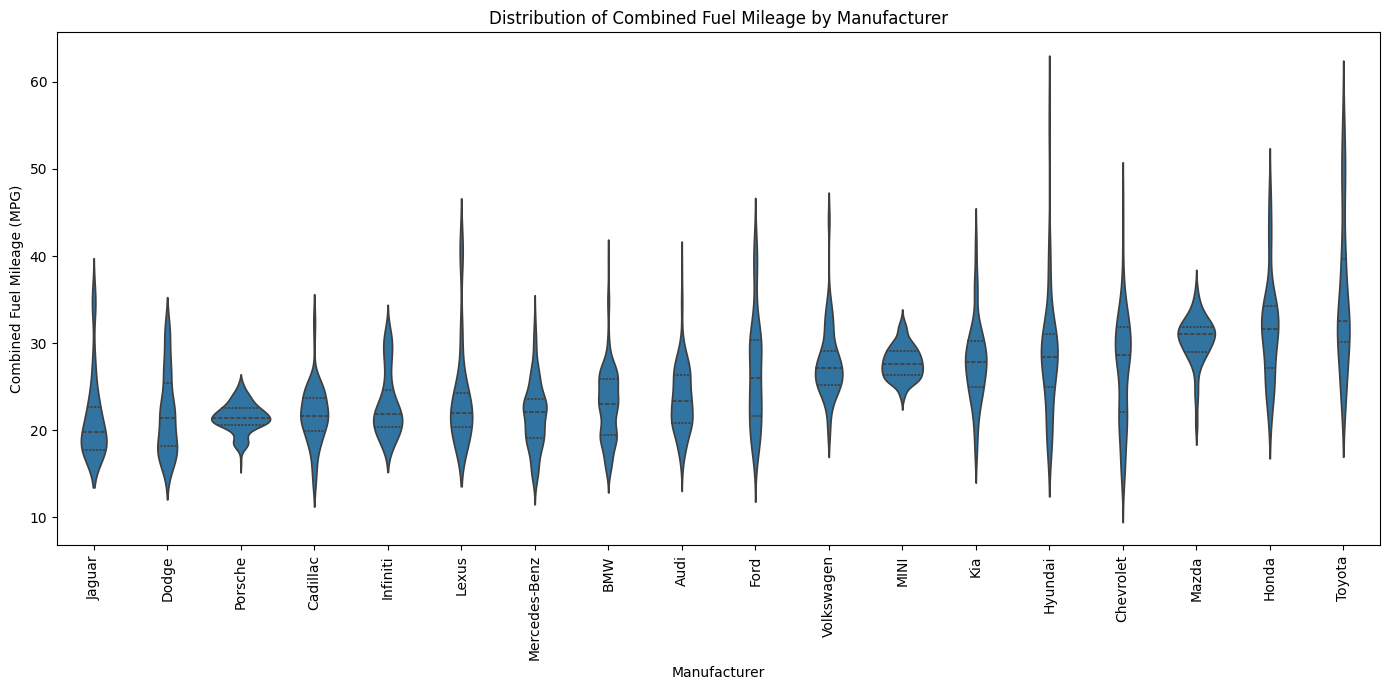

In [6]:
# Task 1: Plot the distribution of combined fuel mileage by manufacturer

# Count the number of cars for each manufacturer
make_counts = fuel_econ['make'].value_counts()

# Select manufacturers with at least 80 cars
top_makes = make_counts[make_counts >= 80].index

# Filter the dataset
fuel_econ_subset = fuel_econ[fuel_econ['make'].isin(top_makes)].copy()

# Order manufacturers by median combined fuel mileage
make_order = (
    fuel_econ_subset.groupby('make')['comb']
    .median()
    .sort_values()
    .index
)

# Create the violin plot
plt.figure(figsize=(14, 7))

sb.violinplot(
    data=fuel_econ_subset,
    x='make',
    y='comb',
    order=make_order,
    inner='quartile'
)

# Add title and labels
plt.title('Distribution of Combined Fuel Mileage by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Combined Fuel Mileage (MPG)')

# Rotate manufacturer labels
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()



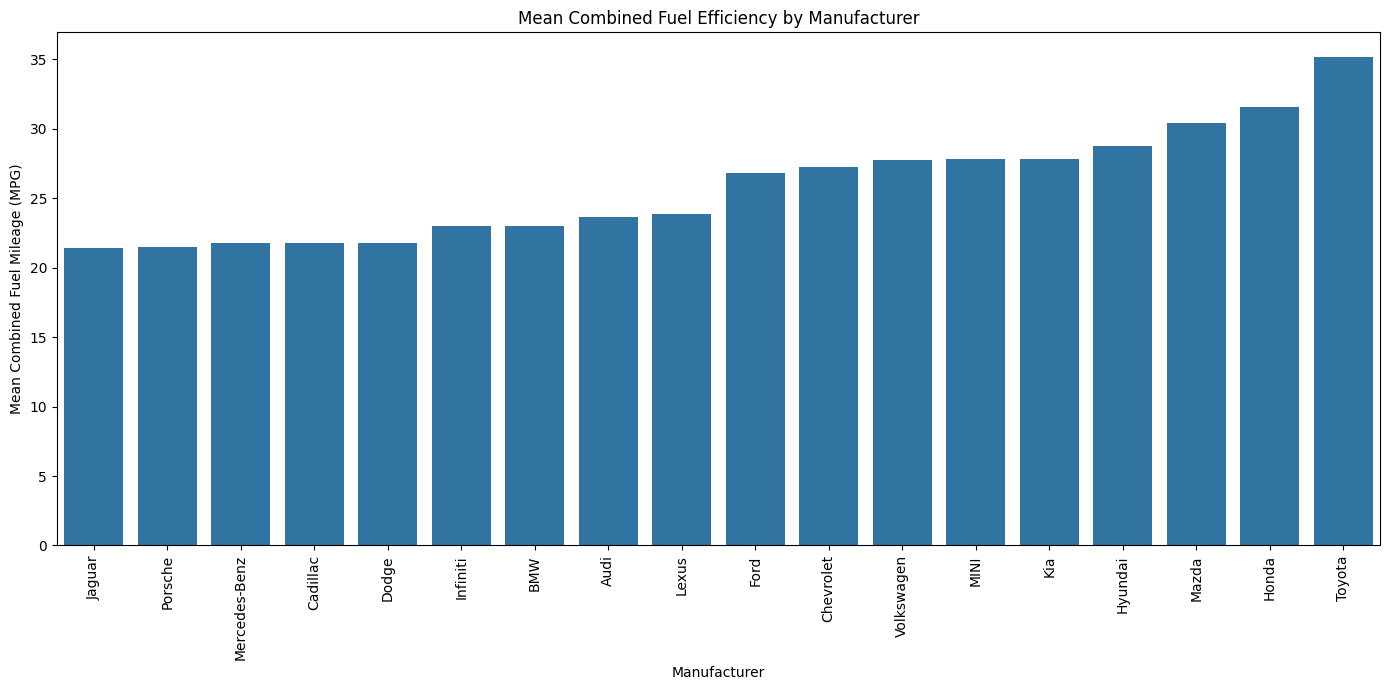

In [7]:
# Task 2: Plot mean combined fuel efficiency by manufacturer

# Calculate the mean combined fuel mileage for each manufacturer
mean_fuel = (
    fuel_econ_subset.groupby('make')['comb']
    .mean()
    .sort_values()
)

# Create a bar plot
plt.figure(figsize=(14, 7))

sb.barplot(
    data=fuel_econ_subset,
    x='make',
    y='comb',
    order=mean_fuel.index,
    errorbar=None
)

# Add title and labels
plt.title('Mean Combined Fuel Efficiency by Manufacturer')
plt.xlabel('Manufacturer')
plt.ylabel('Mean Combined Fuel Mileage (MPG)')

# Rotate manufacturer labels
plt.xticks(rotation=90)

plt.tight_layout()
plt.show()